In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.notebook import trange, tqdm
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

### Load dataset

In [2]:
import scipy.io as sio
import pandas as pd
import numpy as np

import pandas as pd

# Carica il file di testo (rileva automaticamente i nomi delle colonne dalla prima riga)
df = pd.read_csv('Dataset_BH_distribution.txt', sep=r'\s+')

# 1. Estrai la lista dei nomi delle colonne in una variabile
column_names = df.columns.tolist()

print("Variabile column_names creata:")
print(column_names)

print("\nAnteprima dei dati caricati:")
print(df.tail(100))

Variabile column_names creata:
['B_magn_T', 'TPU_L_mm', 't_index', 't_val_s', 'x_coord_m', 'H_val_Am', 'B_val_T']

Anteprima dei dati caricati:
        B_magn_T  TPU_L_mm  t_index  t_val_s  x_coord_m       H_val_Am  \
872540       1.2        40       97  0.04224   0.034056   11235.833619   
872541       1.2        40       97  0.04224   0.035629    9256.116355   
872542       1.2        40       97  0.04224   0.036923    6805.273151   
872543       1.2        40       97  0.04224   0.038000    3550.060193   
872544       1.2        40       98  0.04268   0.000000  117243.533350   
...          ...       ...      ...      ...        ...            ...   
872635       1.2        40      101  0.04400   0.032298   13144.772349   
872636       1.2        40      101  0.04400   0.034056   11299.419729   
872637       1.2        40      101  0.04400   0.035629    9317.507699   
872638       1.2        40      101  0.04400   0.036923    6848.695229   
872639       1.2        40      101  0.044

In [3]:
# original  dataset shape

print("Shape del dataset:", df.shape)

# extract the last column name
nome_ultima_colonna = df.columns[-1]

df_estratto = df[['B_magn_T','TPU_L_mm','t_index','x_coord_m' ,nome_ultima_colonna]]

print("Shape del dataset estratto:", df_estratto.shape)

Shape del dataset: (872640, 7)
Shape del dataset estratto: (872640, 5)


In [4]:
# create the dataset for the NN
# ho 20 punti sull'asse x

df_filtrato = df_estratto[df_estratto['t_index'] == 1]
print("Shape del dataset filtrato:", df_filtrato.shape)
print(df_filtrato.iloc[0:100])

Shape del dataset filtrato: (8640, 5)
      B_magn_T  TPU_L_mm  t_index  x_coord_m  B_val_T
0          0.0        20        1   0.000000      0.0
1          0.0        20        1   0.000533      0.0
2          0.0        20        1   0.001180      0.0
3          0.0        20        1   0.001965      0.0
4          0.0        20        1   0.002917      0.0
...        ...       ...      ...        ...      ...
9595       0.0        25        1   0.000000      0.0
9596       0.0        25        1   0.000668      0.0
9597       0.0        25        1   0.001462      0.0
9598       0.0        25        1   0.002422      0.0
9599       0.0        25        1   0.003582      0.0

[100 rows x 5 columns]


In [5]:
# rremove the rows where B_magn_T is zero

df_senza_zero = df_filtrato[df_filtrato['B_magn_T'] != 0]

In [6]:
print(df_senza_zero.shape)
print(df_senza_zero.iloc[0:100])

(8208, 5)
       B_magn_T  TPU_L_mm  t_index  x_coord_m   B_val_T
43632  0.063158        20        1   0.000000  0.046150
43633  0.063158        20        1   0.000533  0.074075
43634  0.063158        20        1   0.001180  0.089480
43635  0.063158        20        1   0.001965  0.094368
43636  0.063158        20        1   0.002917  0.092789
...         ...       ...      ...        ...       ...
53227  0.063158        25        1   0.000000  0.044722
53228  0.063158        25        1   0.000668  0.070021
53229  0.063158        25        1   0.001462  0.082910
53230  0.063158        25        1   0.002422  0.085624
53231  0.063158        25        1   0.003582  0.082119

[100 rows x 5 columns]


In [ ]:
# df_filtrato is our dataset: DECIDES the INPUTS and OUTPUTS

# INPUT: B_magn_T, TPU_L_mm, x_coord_m
x = df_senza_zero[['B_magn_T','TPU_L_mm','x_coord_m']].values
# OUTPUT: B_val_T
y = df_senza_zero['B_val_T'].values

# check shapes

print(x.shape, y.shape)

(8208, 3) (8208,)


In [8]:
# check what's inside if u are interested
print(y)

[0.04614992 0.07407523 0.08948004 ... 0.06847514 0.04997008 0.02593843]


In [9]:
# set up the training, validationa nd test sets
# the function "train_test_split"  divides the dataset into two parts: one for training
#  and one for testing. Hence to get 3 sets we need to call it twice. we will divide the test set obtained from the first cut

# N.B. ALWAYS DIVIDE AND THEN SCALE, NEVER SCALE AND THEN DIVIDE, 
# OTHERWISE YOU RISK TO HAVE DATA LEAKAGE 
# (INFORMATION FROM THE TEST SET IN THE TRAINING SET)


# =============== SPLIT THE DATASET INTO TRAIN, VAL AND TEST SETS ===============
X_train, X_test_1stcut, y_train, y_test_1stcut = train_test_split(x, y, test_size=0.3, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_test_1stcut, y_test_1stcut, test_size=0.5, random_state=42)
# ================================================================


# Initialize the [0,1] scaler
scaler_X = MinMaxScaler()

# aplly the scaling (x-xmin)/(xmax-xmin) to TRAIN
X_train_scaled = scaler_X.fit_transform(X_train)

# apply the same transformation to VAL
X_val_scaled = scaler_X.transform(X_val)

# apply the same transformation to TEST
X_test_scaled = scaler_X.transform(X_test)


#the scaling on the B(x) (OUTPUT) is not needed because the values 
# are already between 0 and 1 more or less, so we can skip it

In [10]:
# shape check
print(X_train_scaled.shape, y_train.shape)
print(X_val_scaled.shape, y_val.shape)
print(X_test_scaled.shape, y_test.shape)

(5745, 3) (5745,)
(1232, 3) (1232,)
(1231, 3) (1231,)


### NN initialization

In [11]:
# initialize the NN

class NN_get_BofX(nn.Module):
    def __init__(self, n_input, n_output, n_hidden1=64,n_hidden2=32):
        super(NN_get_BofX, self).__init__()
        self.fc1 = nn.Linear(n_input, n_hidden1)  # 3 input features, 64 hidden units
        self.fc2 = nn.Linear(n_hidden1, n_hidden2) # 64 hidden units, 32 hidden units
        self.fc3 = nn.Linear(n_hidden2, n_output)  # 32 hidden units, 1 output
        self.relu = nn.ReLU()
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [12]:
# convert SCALED data to torch tensors


X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)


y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)


# shape check
print(X_train_tensor.shape, y_train_tensor.shape)
print(X_test_tensor.shape, y_test_tensor.shape)
print(X_val_tensor.shape, y_val_tensor.shape)



torch.Size([5745, 3]) torch.Size([5745, 1])
torch.Size([1231, 3]) torch.Size([1231, 1])
torch.Size([1232, 3]) torch.Size([1232, 1])


In [13]:
# group everything for BATCH TRAINING
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)


train_data = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
val_data   = DataLoader(dataset=val_dataset,   batch_size=64, shuffle=False)
test_data  = DataLoader(dataset=test_dataset,  batch_size=64, shuffle=False)

In [14]:
# Initialize all u need for the NN trainign loop

n_input = X_train_tensor.shape[1]
n_output = y_train_tensor.shape[1]
model = NN_get_BofX(n_input,n_output)
loss_criterion = nn.MSELoss()
eta = 1e-3 # Learning Rate
optimizer = optim.Adam(model.parameters(), lr=eta)
n_epochs = 100

In [15]:
def train_model(model, train_data, loss_criterion, optimizer, loss_logger, epoch_idx):
  total_loss = 0
  for batch_idx, (data,target) in enumerate(tqdm(train_data, desc="Training", leave=False)):
    pred_output = model(data)
    loss = loss_criterion(pred_output, target)
    optimizer.zero_grad() # Clears all gradients; prevent gradient accumulation
    loss.backward() # Computes gradient of loss wrt model parameters
    optimizer.step() # Updates model paraments using computed gradients
    #loss_logger.append(loss.item()) # Logs the loss; convenient if batch_size = dataset_size
    # .item() - Converts tensor into a python number
    total_loss += loss.item() # Track/accumulate the loss

  avg_loss = total_loss / len(train_data) # Compute the average loss
  loss_logger.append(avg_loss) # Store the loss

  #print(f"Epoch: {epoch_idx} | Loss: {avg_loss:.4f}")


  return model, optimizer, loss_logger

In [16]:
def validate_model(model, val_data, loss_criterion, val_loss_logger):
    model.eval() # Set to evaluation mode
    total_loss = 0
    with torch.no_grad():
        for data, target in val_data:
            pred_output = model(data)
            loss = loss_criterion(pred_output, target)
            total_loss += loss.item()

    avg_loss = total_loss / len(val_data)
    val_loss_logger.append(avg_loss)
    return val_loss_logger

In [17]:
def test_model(model, test_data, loss_criterion, loss_logger):
  total_loss = 0
  with torch.no_grad():
    for batch_idx, (data,target) in enumerate(tqdm(test_data, desc="Testing", leave=False)):
      pred_output = model(data)
      loss = loss_criterion(pred_output, target)
      #loss_logger.append(loss.item())
      total_loss += loss.item()

    avg_loss = total_loss / len(test_data)
    loss_logger.append(avg_loss)

    return loss_logger

In [18]:
train_loss = []
val_loss = []
test_loss = []

for i in trange(n_epochs, desc="Epoch", leave=False):
    # Train
    model, optimizer, train_loss = train_model(model, train_data, loss_criterion, optimizer, train_loss, epoch_idx=i)

    # Validate (Check performance on unseen "practice" data)
    val_loss = validate_model(model, val_data, loss_criterion, val_loss)

    # Optional: Print progress
    # print(f"Epoch {i}: Train Loss: {train_loss[-1]:.4f} | Val Loss: {val_loss[-1]:.4f}")


# 3. Test (Only once, after all epochs are finished)
test_loss = test_model(model, test_data, loss_criterion, test_loss)



Epoch:   0%|          | 0/100 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

... (92 outputs left out)

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Testing:   0%|          | 0/20 [00:00<?, ?it/s]

In [19]:
# Assess final results (solution)

def assess_results(model, X, y, data_type):
    model.eval()
    with torch.no_grad():
        y_hat = model(X)

        # Prediction and plotting
        #plt.figure(figsize = (4, 4))
        #plt.plot(y_hat.numpy(), 'r-', label='Predicted output')
        #plt.plot(y.numpy(), 'b-', label='True output')
        #plt.title(f'Predicted vs Estimated output: {data_type} dataset')  # Fixed f-string
        #plt.legend()
        #plt.show()

        # Prediction and plotting
        plt.figure(figsize = (2, 2))
        plt.scatter(y_hat.numpy(), y.numpy())
        plt.xlabel('Predicted output')
        plt.ylabel('True output')
        plt.title(f'Predicted vs Estimated output: {data_type} dataset')  # Fixed f-string
        plt.legend()
        plt.grid(True)
        plt.show()

        # RMSE calculation
        mse = torch.mean((y_hat - y) ** 2)
        rmse = torch.sqrt(mse)


        # R2 calculation
        total_variance = torch.var(y)
        residual_variance = torch.mean((y_hat - y) ** 2)
        R2 = 1 - residual_variance / total_variance

    return rmse, R2


C:\Users\utente1\AppData\Local\Temp\ipykernel_14240\2641201775.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


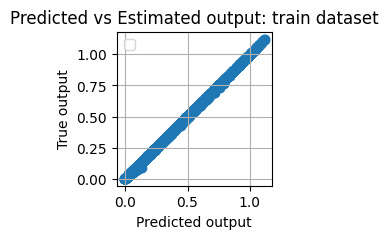

Training results
rmse = 0.0043. R2 = 1.000


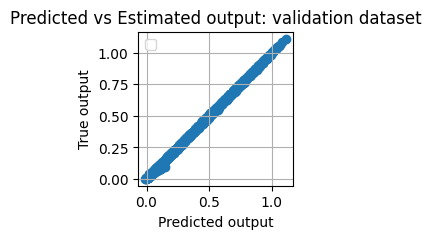

Validation results
rmse = 0.0048. R2 = 1.000


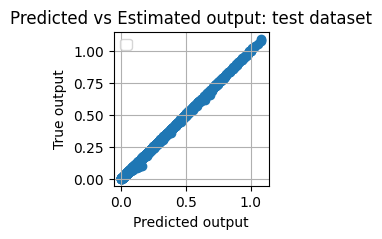

Test results
rmse = 0.0049. R2 = 1.000


In [20]:
# Assess results in training
rmse_train, R2_train = assess_results(model, X_train_tensor, y_train_tensor.view(-1,1), data_type = 'train')
print('Training results')
print(f"rmse = {rmse_train:.4f}. R2 = {R2_train:.3f}")

# Assess results in validation
rmse_val, R2_val = assess_results(model, X_val_tensor, y_val_tensor.view(-1,1), data_type = 'validation')
print('Validation results')
print(f"rmse = {rmse_val:.4f}. R2 = {R2_val:.3f}")

# Assess results in test
rmse_test, R2_test = assess_results(model, X_test_tensor, y_test_tensor.view(-1,1), data_type = 'test')
print('Test results')
print(f"rmse = {rmse_test:.4f}. R2 = {R2_test:.3f}")

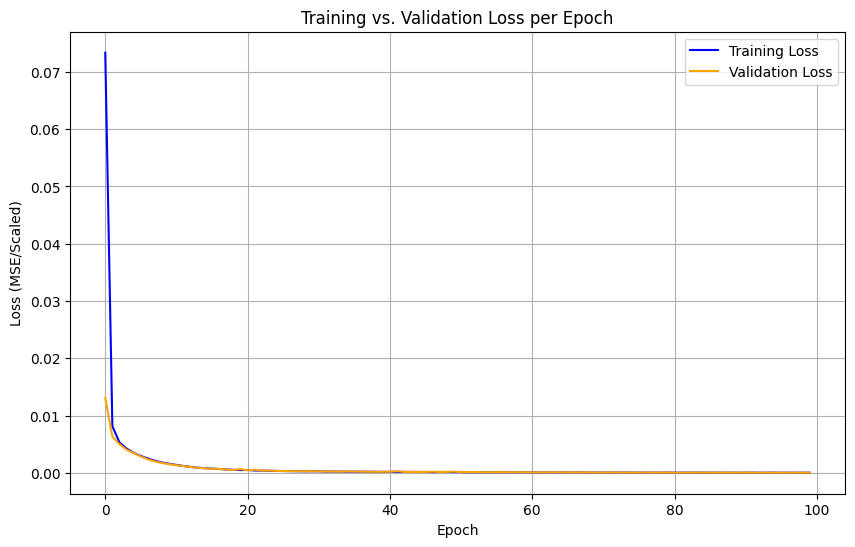

Final Training Loss: 0.000022
Final Validation Loss: 0.000023
Final Test Loss: 0.0000


In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plotting both on the same axes
plt.plot(train_loss, label='Training Loss', color='blue')
plt.plot(val_loss, label='Validation Loss', color='orange')

# Training and Validation Plot
plt.title('Training vs. Validation Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE/Scaled)')
plt.legend()
plt.grid(True)
plt.show()


print(f"Final Training Loss: {train_loss[-1]:.6f}")
print(f"Final Validation Loss: {val_loss[-1]:.6f}")
print(f"Final Test Loss: {test_loss[-1]:.4f}")

### Assessment and inference

In [22]:
X_test_tensor.shape

torch.Size([1231, 3])

In [23]:
# extract from the test set
k = 1 # index of the sample you want to extract
X_test_tensor_TRY = X_test_tensor[k,:]

print(X_test_tensor_TRY)
# scale it back to the original values (inverse transform)
X_test_tensor_TRY_np = X_test_tensor_TRY.numpy().reshape(1, -1) # reshape to 2D array for inverse transform
X_test_tensor_TRY_np_original = scaler_X.inverse_transform(X_test_tensor_TRY_np)
print(X_test_tensor_TRY_np_original)

tensor([0.4444, 0.5500, 0.0228])
[[5.6842107e-01 3.1000000e+01 8.6461066e-04]]


In [24]:
# pass to the NN and get the prediction
model.eval()
with torch.no_grad():
    y_test_tensor_TRY = model(X_test_tensor_TRY)
print(y_test_tensor_TRY)

tensor([0.5798])


In [ ]:
prova = scaler_X.transform([[0.5, 30, 0.028]])
print(prova)

model.eval()
with torch.no_grad():
    y_test_tensor_TRY = model(torch.tensor(prova, dtype=torch.float32))
print(y_test_tensor_TRY)

[[0.38425926 0.5        0.78947368]]
tensor([[-0.0307]])


In [26]:
#try on the whole test set
y_TEST = []
X_test_scaledTOoriginal = []
model.eval()
with torch.no_grad():
    for i in range(X_test_tensor.shape[0]):
        X_test_tensor_ith = X_test_tensor[i,:] # extract the first sample of the test set
        X_test_tensor_ith_np = X_test_tensor_ith.numpy().reshape(1, -1) # reshape to 2D array for inverse transform
        X_test_tensor_ith_np_original = scaler_X.inverse_transform(X_test_tensor_ith_np)

        y_test_tensor_ith = model(X_test_tensor_ith)
        y_TEST.append(y_test_tensor_ith.item()) # store the prediction in a list
        X_test_scaledTOoriginal.append(X_test_tensor_ith_np_original) # store the scaled and original features in a list


In [27]:
# shape check
print(X_test_tensor.shape)
print(len(y_TEST))

torch.Size([1231, 3])
1231


In [28]:
# print the results with the corresponding INPUTS
for i in range(len(y_TEST)):
    print(f"Predicted B(x) = {y_TEST[i]:.4f} for input features (B_magn_T, TPU_L_mm, x_coord_m) = {X_test_scaledTOoriginal[i][0]}")

Predicted B(x) = 0.4146 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [6.315790e-01 4.000000e+01 9.248009e-03]
Predicted B(x) = 0.5798 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [5.6842107e-01 3.1000000e+01 8.6461066e-04]
Predicted B(x) = 0.0139 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [1.2631579e-01 2.9000000e+01 2.5847338e-02]
Predicted B(x) = 0.1198 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [7.5789475e-01 3.8000000e+01 2.5203696e-02]
Predicted B(x) = 0.0099 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [3.157895e-01 3.400000e+01 3.230000e-02]
Predicted B(x) = 1.0071 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [1.0736842e+00 2.8000000e+01 1.7393910e-03]
Predicted B(x) = 0.0633 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [6.315789e-02 2.500000e+01 6.624297e-03]
Predicted B(x) = 0.0821 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [8.8421053e-01 3.5000000e+01 2.9784566e-02]
Predicted B(x) = 0.6795 for input feature

In [29]:
# 1. Creiamo una lista di indici ordinati in base alla coordinata x_coord_m
# Assumiamo che x sia l'elemento in posizione 2: feat[0][2]
indici_ordinati = sorted(
    range(len(y_TEST)), 
    key=lambda idx: X_test_scaledTOoriginal[idx][0][2]  # Ordina per x crescente
)

# 2. Riorganizziamo le liste usando gli indici ordinati
y_TEST_ordinato = [y_TEST[i] for i in indici_ordinati]
X_test_scaled_ordinato = [X_test_scaledTOoriginal[i] for i in indici_ordinati]

# 3. Stampa pulita e ordinata
for i in range(len(y_TEST_ordinato)):
    print(f"Predicted B(x) = {y_TEST_ordinato[i]:.4f} for input features (B_magn_T, TPU_L_mm, x_coord_m) = {X_test_scaled_ordinato[i][0]}")

Predicted B(x) = 0.4880 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [ 0.75789475 34.          0.        ]
Predicted B(x) = 0.5401 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [ 0.8210527 27.         0.       ]
Predicted B(x) = 0.0442 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [ 0.06315789 23.          0.        ]
Predicted B(x) = 0.5665 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [ 0.8842105 35.         0.       ]
Predicted B(x) = 0.6711 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [ 1.0736842 37.         0.       ]
Predicted B(x) = 0.6178 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [ 0.94736844 23.          0.        ]
Predicted B(x) = 0.3530 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [ 0.50526315 21.          0.        ]
Predicted B(x) = 0.6674 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [ 1.0736842 38.         0.       ]
Predicted B(x) = 0.7343 for input features (B_magn_T, TPU_L_mm, x_coord_m) = [ 1.2 33.   0. 

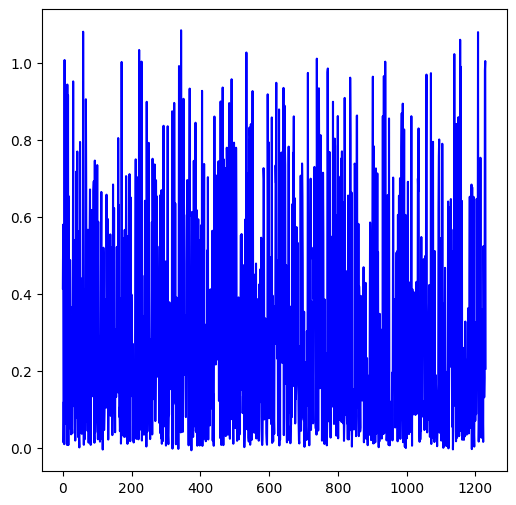

In [30]:
# plot of the predicted B(x) vs the samples of test set

plt.figure(figsize=(6, 6))

plt.plot(range(len(y_TEST)), y_TEST, color='blue', label='Predicted vs True')

### Prediction

In [31]:
# reconstruction of the B(x) curve for a given L and B_magn_T

L_target = 30 # mm
B_magn_T_target = 0.25 # T

# get 20 points along such L
x_points = torch.linspace(0, L_target/1000, 20)

# shape check
x_points.shape

torch.Size([20])

In [32]:
# set the input dataset

matrice_input = torch.zeros(20, 3)

# Inserisci x_points nella prima colonna
matrice_input[:, 2] = x_points

# Assegni i valori scalari alle altre colonne (PyTorch li ripete in automatico)
matrice_input[:, 1] = L_target
matrice_input[:, 0] = B_magn_T_target

print(matrice_input)


tensor([[2.5000e-01, 3.0000e+01, 0.0000e+00],
        [2.5000e-01, 3.0000e+01, 1.5789e-03],
        [2.5000e-01, 3.0000e+01, 3.1579e-03],
        [2.5000e-01, 3.0000e+01, 4.7368e-03],
        [2.5000e-01, 3.0000e+01, 6.3158e-03],
        [2.5000e-01, 3.0000e+01, 7.8947e-03],
        [2.5000e-01, 3.0000e+01, 9.4737e-03],
        [2.5000e-01, 3.0000e+01, 1.1053e-02],
        [2.5000e-01, 3.0000e+01, 1.2632e-02],
        [2.5000e-01, 3.0000e+01, 1.4211e-02],
        [2.5000e-01, 3.0000e+01, 1.5789e-02],
        [2.5000e-01, 3.0000e+01, 1.7368e-02],
        [2.5000e-01, 3.0000e+01, 1.8947e-02],
        [2.5000e-01, 3.0000e+01, 2.0526e-02],
        [2.5000e-01, 3.0000e+01, 2.2105e-02],
        [2.5000e-01, 3.0000e+01, 2.3684e-02],
        [2.5000e-01, 3.0000e+01, 2.5263e-02],
        [2.5000e-01, 3.0000e+01, 2.6842e-02],
        [2.5000e-01, 3.0000e+01, 2.8421e-02],
        [2.5000e-01, 3.0000e+01, 3.0000e-02]])


In [33]:
# compare it to DATASET
condizione_B = df_senza_zero['B_magn_T'] == 0.5
condizione_L = df_senza_zero['TPU_L_mm'] == 30

# Applica il filtro (ricorda le parentesi tonde attorno a ciascuna condizione!)
df_target = df_senza_zero[condizione_B & condizione_L]

print("Numero di righe trovate:", df_target.shape[0])
print(df_target.head())

Numero di righe trovate: 0
Empty DataFrame
Columns: [B_magn_T, TPU_L_mm, t_index, x_coord_m, B_val_T]
Index: []


In [34]:
# get the INPUTS for the NN
X_input = matrice_input.float()
X_input = scaler_X.transform(X_input)
X_input_tensor = torch.tensor(X_input, dtype=torch.float32)

In [35]:
model.eval()
with torch.no_grad():
    y_input = model(X_input_tensor)
print(y_input.shape)
print(y_input)

torch.Size([20, 1])
tensor([[ 0.1663],
        [ 0.3109],
        [ 0.3124],
        [ 0.2891],
        [ 0.2566],
        [ 0.2245],
        [ 0.1903],
        [ 0.1544],
        [ 0.1267],
        [ 0.1038],
        [ 0.0875],
        [ 0.0759],
        [ 0.0662],
        [ 0.0565],
        [ 0.0463],
        [ 0.0398],
        [ 0.0299],
        [ 0.0200],
        [ 0.0108],
        [-0.0321]])


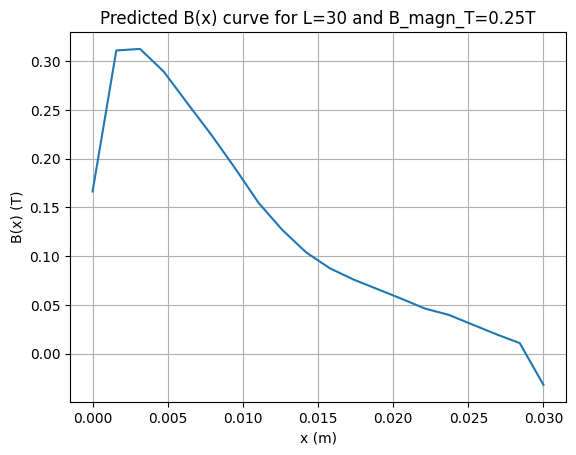

In [ ]:
plt.figure()
plt.plot(x_points.numpy(), y_input.numpy())
plt.title(f'PREDICTED B(x) curve for L={L_target} and B_magn_T={B_magn_T_target}T')
plt.xlabel('x (m)')
plt.ylabel('B(x) (T)')
plt.grid(True)
plt.show()

### True value

In [39]:
# extract a B(x) curve from the dataset for the same L and B_magn_T
x_dataset = df_senza_zero['x_coord_m'].values
x_dataset

array([0.        , 0.00053318, 0.00118007, ..., 0.035629  , 0.03692343,
       0.038     ], shape=(8208,))

In [ ]:
condizione_reset = df_senza_zero["x_coord_m"] == 0
df_senza_zero["blocco_id"] = condizione_reset.cumsum()
df_senza_zero.head(40)


C:\Users\utente1\AppData\Local\Temp\ipykernel_14240\3225599855.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_senza_zero["blocco_id"] = condizione_reset.cumsum()


(8208,)

In [91]:
# extract the 3 columns
df_plot = df_senza_zero[['B_magn_T','TPU_L_mm','x_coord_m','B_val_T','blocco_id']]
df_plot_block = df_plot[df_plot['blocco_id'] == 150]
df_plot['blocco_id'].max()
df_plot_block.head(50)


,B_magn_T,TPU_L_mm,x_coord_m,B_val_T,blocco_id
352894,0.505263,22,0.000000,0.350145,150
352895,0.505263,22,0.000588,0.555878,150
352896,0.505263,22,0.001291,0.636846,150
352897,0.505263,22,0.002143,0.652456,150
352898,0.505263,22,0.003174,0.632787,150
352899,0.505263,22,0.004422,0.587655,150
352900,0.505263,22,0.005866,0.525150,150
352901,0.505263,22,0.007393,0.457503,150
352902,0.505263,22,0.008922,0.393798,150
352903,0.505263,22,0.010450,0.335390,150


In [ ]:
# extract the scalar real data:

# define the target u want:

B_magn_T_target_true = df_plot_block['B_magn_T'].iloc[0] # T
L_target_true = df_plot_block['TPU_L_mm'].iloc[0] # mm

print(f"Target B_magn_T: {B_magn_T_target_true} T, Target L: {L_target_true} mm")



Target B_magn_T: 0.505263157894737 T, Target L: 22 mm


In [93]:
# extract the B(x) curve for the same L and B_magn_T
vec_coord = df_plot_block['x_coord_m'].values
vec_B = df_plot_block['B_val_T'].values

print(vec_coord.shape)
print(vec_B.shape)

(19,)
(19,)


Text(0.5, 1.0, 'Real B(x) curve for L=22 mm and B_magn_T=0.505263157894737 T')

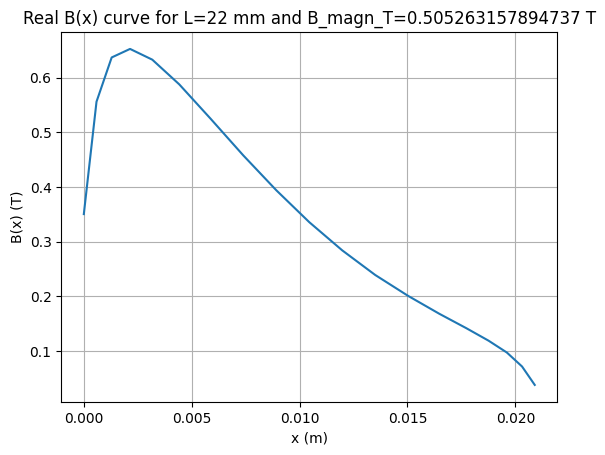

In [ ]:
# do the plot

plt.figure()
plt.plot(vec_coord, vec_B, label='Real B(x) curve')
plt.grid(True)
plt.xlabel('x (m)')
plt.ylabel('B(x) (T)')  
plt.title(f'REAL B(x) curve for L={L_target_true} mm and B_magn_T={B_magn_T_target_true} T')

### Comparison

In [107]:
print(len(vec_coord))

points_on_axis = 100

19


In [108]:
# reconstruction of the B(x) PREDICTED curve for a given L and B_magn_T

L_target_NN = L_target_true  # mm
B_magn_T_target_NN = B_magn_T_target_true # T

# get 20 points along such L
x_points = torch.linspace(0, L_target_NN/1000, points_on_axis) #len(vec_coord)

# shape check
print(x_points.shape)
print(x_points)
print(L_target_NN)

torch.Size([100])
tensor([0.0000, 0.0002, 0.0004, 0.0007, 0.0009, 0.0011, 0.0013, 0.0016, 0.0018,
        0.0020, 0.0022, 0.0024, 0.0027, 0.0029, 0.0031, 0.0033, 0.0036, 0.0038,
        0.0040, 0.0042, 0.0044, 0.0047, 0.0049, 0.0051, 0.0053, 0.0056, 0.0058,
        0.0060, 0.0062, 0.0064, 0.0067, 0.0069, 0.0071, 0.0073, 0.0076, 0.0078,
        0.0080, 0.0082, 0.0084, 0.0087, 0.0089, 0.0091, 0.0093, 0.0096, 0.0098,
        0.0100, 0.0102, 0.0104, 0.0107, 0.0109, 0.0111, 0.0113, 0.0116, 0.0118,
        0.0120, 0.0122, 0.0124, 0.0127, 0.0129, 0.0131, 0.0133, 0.0136, 0.0138,
        0.0140, 0.0142, 0.0144, 0.0147, 0.0149, 0.0151, 0.0153, 0.0156, 0.0158,
        0.0160, 0.0162, 0.0164, 0.0167, 0.0169, 0.0171, 0.0173, 0.0176, 0.0178,
        0.0180, 0.0182, 0.0184, 0.0187, 0.0189, 0.0191, 0.0193, 0.0196, 0.0198,
        0.0200, 0.0202, 0.0204, 0.0207, 0.0209, 0.0211, 0.0213, 0.0216, 0.0218,
        0.0220])
22


In [109]:
# set the input dataset

matrice_input = torch.zeros(points_on_axis, 3) # len(vec_coord)

# Inserisci x_points nella prima colonna
matrice_input[:, 2] = x_points

# Assegni i valori scalari alle altre colonne (PyTorch li ripete in automatico)
matrice_input[:, 1] = L_target_NN
matrice_input[:, 0] = B_magn_T_target_NN

print(matrice_input)


tensor([[5.0526e-01, 2.2000e+01, 0.0000e+00],
        [5.0526e-01, 2.2000e+01, 2.2222e-04],
        [5.0526e-01, 2.2000e+01, 4.4444e-04],
        [5.0526e-01, 2.2000e+01, 6.6667e-04],
        [5.0526e-01, 2.2000e+01, 8.8889e-04],
        [5.0526e-01, 2.2000e+01, 1.1111e-03],
        [5.0526e-01, 2.2000e+01, 1.3333e-03],
        [5.0526e-01, 2.2000e+01, 1.5556e-03],
        [5.0526e-01, 2.2000e+01, 1.7778e-03],
        [5.0526e-01, 2.2000e+01, 2.0000e-03],
        [5.0526e-01, 2.2000e+01, 2.2222e-03],
        [5.0526e-01, 2.2000e+01, 2.4444e-03],
        [5.0526e-01, 2.2000e+01, 2.6667e-03],
        [5.0526e-01, 2.2000e+01, 2.8889e-03],
        [5.0526e-01, 2.2000e+01, 3.1111e-03],
        [5.0526e-01, 2.2000e+01, 3.3333e-03],
        [5.0526e-01, 2.2000e+01, 3.5556e-03],
        [5.0526e-01, 2.2000e+01, 3.7778e-03],
        [5.0526e-01, 2.2000e+01, 4.0000e-03],
        [5.0526e-01, 2.2000e+01, 4.2222e-03],
        [5.0526e-01, 2.2000e+01, 4.4444e-03],
        [5.0526e-01, 2.2000e+01, 4

In [110]:
# get the INPUTS for the NN
X_input = matrice_input.float()
X_input = scaler_X.transform(X_input)
X_input_tensor = torch.tensor(X_input, dtype=torch.float32)

In [116]:
print(X_input_tensor)
print(L_target_NN)

tensor([[0.3889, 0.1000, 0.0000],
        [0.3889, 0.1000, 0.0058],
        [0.3889, 0.1000, 0.0117],
        [0.3889, 0.1000, 0.0175],
        [0.3889, 0.1000, 0.0234],
        [0.3889, 0.1000, 0.0292],
        [0.3889, 0.1000, 0.0351],
        [0.3889, 0.1000, 0.0409],
        [0.3889, 0.1000, 0.0468],
        [0.3889, 0.1000, 0.0526],
        [0.3889, 0.1000, 0.0585],
        [0.3889, 0.1000, 0.0643],
        [0.3889, 0.1000, 0.0702],
        [0.3889, 0.1000, 0.0760],
        [0.3889, 0.1000, 0.0819],
        [0.3889, 0.1000, 0.0877],
        [0.3889, 0.1000, 0.0936],
        [0.3889, 0.1000, 0.0994],
        [0.3889, 0.1000, 0.1053],
        [0.3889, 0.1000, 0.1111],
        [0.3889, 0.1000, 0.1170],
        [0.3889, 0.1000, 0.1228],
        [0.3889, 0.1000, 0.1287],
        [0.3889, 0.1000, 0.1345],
        [0.3889, 0.1000, 0.1404],
        [0.3889, 0.1000, 0.1462],
        [0.3889, 0.1000, 0.1520],
        [0.3889, 0.1000, 0.1579],
        [0.3889, 0.1000, 0.1637],
        [0.388

In [111]:
model.eval()
with torch.no_grad():
    y_input = model(X_input_tensor)
print(y_input.shape)
print(y_input)

torch.Size([100, 1])
tensor([[ 0.3533],
        [ 0.3990],
        [ 0.4987],
        [ 0.6015],
        [ 0.6502],
        [ 0.6533],
        [ 0.6564],
        [ 0.6581],
        [ 0.6579],
        [ 0.6575],
        [ 0.6558],
        [ 0.6541],
        [ 0.6524],
        [ 0.6478],
        [ 0.6418],
        [ 0.6342],
        [ 0.6265],
        [ 0.6189],
        [ 0.6108],
        [ 0.6018],
        [ 0.5922],
        [ 0.5826],
        [ 0.5730],
        [ 0.5634],
        [ 0.5538],
        [ 0.5441],
        [ 0.5345],
        [ 0.5249],
        [ 0.5153],
        [ 0.5057],
        [ 0.4961],
        [ 0.4865],
        [ 0.4769],
        [ 0.4667],
        [ 0.4565],
        [ 0.4463],
        [ 0.4361],
        [ 0.4259],
        [ 0.4158],
        [ 0.4057],
        [ 0.3956],
        [ 0.3855],
        [ 0.3754],
        [ 0.3664],
        [ 0.3577],
        [ 0.3491],
        [ 0.3412],
        [ 0.3333],
        [ 0.3254],
        [ 0.3175],
        [ 0.3096],
        [ 

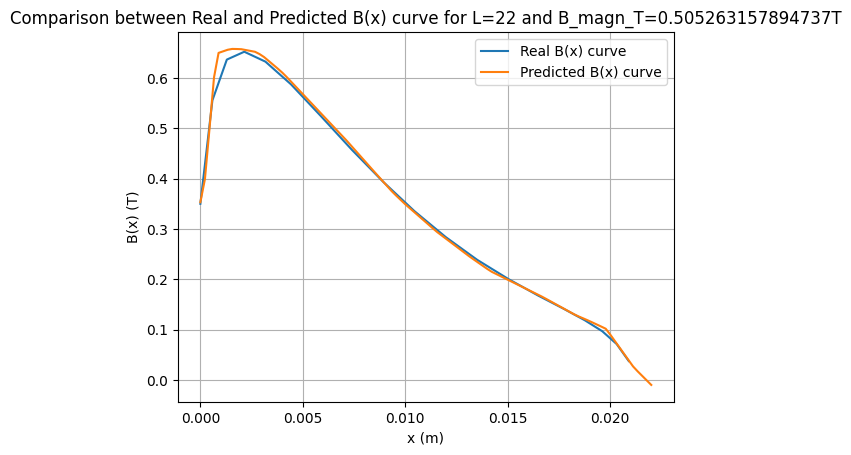

In [114]:
# comparison between the real B(x) curve and the predicted one  

plt.figure()
plt.plot(vec_coord, vec_B, label='Real B(x) curve')
plt.plot(x_points.numpy(), y_input.numpy(), label='Predicted B(x) curve')
plt.title(f'Comparison between Real and Predicted B(x) curve for L={L_target_true} and B_magn_T={B_magn_T_target_true}T')
plt.grid(True)
plt.xlabel('x (m)')
plt.ylabel('B(x) (T)')
plt.legend()    